In [1]:
import tensorflow as tf


2024-12-21 13:16:24.103358: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-12-21 13:16:30.176489: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-12-21 13:16:41.501876: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /usr/local/cuda/lib64:/usr/local/cuda/lib:/usr/local/lib/x86_64-linux-gnu:/usr/local/nvidia/lib:/usr/local/nvidia/lib64:/usr/local/nvidia/lib:/usr/local/nvidia/lib64
2024-12-21 13:16:41.502194: W tensorfl

In [2]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        tf.config.experimental.set_memory_growth(gpus[0], True)
        tf.config.set_visible_devices(gpus[0], 'GPU')
        print("Using GPU:", gpus[0])
    except RuntimeError as e:
        print("Error setting up GPU:", e)
else:
    print("No GPU found, using CPU instead.")


Using GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


2024-12-21 13:16:53.002870: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2024-12-21 13:16:54.012448: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2024-12-21 13:16:54.017439: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero


In [2]:
!pip install opencv-python-headless

  Using cached opencv_python_headless-4.10.0.84-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (20 kB)
Using cached opencv_python_headless-4.10.0.84-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (49.9 MB)


In [3]:
import os
import fnmatch
import cv2
import numpy as np
import string
import time

from tensorflow.keras.utils import pad_sequences
from keras.layers import Dense, LSTM, Reshape, BatchNormalization, Input, Conv2D, MaxPool2D, Lambda, Bidirectional
from keras.models import Model
from keras.activations import relu, sigmoid, softmax
import keras.backend as K
from keras.utils import to_categorical
from keras.callbacks import ModelCheckpoint

2024-12-21 21:02:04.054012: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-12-21 21:02:04.273483: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-12-21 21:02:08.146546: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /opt/conda/lib/python3.10/site-packages/cv2/../../lib64:/usr/local/cuda/lib64:/usr/local/cuda/lib:/usr/local/lib/x86_64-linux-gnu:/usr/local/nvidia/lib:/usr/local/nvidia/lib64:/usr/local/nvidia/lib:/usr/l

In [5]:
file_path='synthdata'
count = 0
for path in os.listdir(file_path):
    if os.path.isfile(os.path.join(file_path, path)):
        count += 1
print('File count:', count)

File count: 90031


In [232]:

images = []
labels = []
root_dir = "synthdata"

for root, _, files in os.walk(root_dir):
    for file_name in files:

        if file_name.lower().endswith(('.png')):
            file_path = os.path.join(root, file_name)

            label = file_path[10::]
            label=label[:-4]

            images.append(file_path)
            labels.append(label)
print("Sample image paths:", images[5000:5005])
print("Sample labels:", labels[5000:5005])


Sample image paths: ['synthdata/proplastid.png', 'synthdata/applicators.png', 'synthdata/unprompted.png', 'synthdata/cadouk.png', 'synthdata/fantasize.png']
Sample labels: ['proplastid', 'applicators', 'unprompted', 'cadouk', 'fantasize']


In [233]:
char_list = list(set(char for label in labels for char in label))
 
def encode_to_labels(txt):
    dig_lst = []
    for index, char in enumerate(txt):
        try:
            dig_lst.append(char_list.index(char))
        except:
            print(char)
        
    return dig_lst

In [9]:
path = 'synthdata'

training_img = []
training_txt = []
train_input_length = []
train_label_length = []
orig_txt = []

valid_img = []
valid_txt = []
valid_input_length = []
valid_label_length = []
valid_orig_txt = []
 
max_label_len = 0
 
i =1 
flag = 0
 
for root, dirnames, filenames in os.walk(path):
    for f_name in fnmatch.filter(filenames, '*.png'):
        img = cv2.cvtColor(cv2.imread(os.path.join(root, f_name)), cv2.COLOR_BGR2GRAY)   
        w, h = img.shape
        if h > 128 or w > 32:
            img = cv2.resize(img, (128, 32))
        if w < 32:
            add_zeros = np.ones((32-w, h))*255
            img = np.concatenate((img, add_zeros))
 
        if h < 128:
            add_zeros = np.ones((32, 128-h))*255
            img = np.concatenate((img, add_zeros), axis=1)
        img = np.expand_dims(img , axis = 2)
        img = img/255.
        txt = f_name[:-4]
        if len(txt) > max_label_len:
            max_label_len = len(txt)

        if i%10 == 0:     
            valid_orig_txt.append(txt)   
            valid_label_length.append(len(txt))
            valid_input_length.append(31)
            valid_img.append(img)
            valid_txt.append(encode_to_labels(txt))
        else:
            orig_txt.append(txt)   
            train_label_length.append(len(txt))
            train_input_length.append(31)
            training_img.append(img)
            training_txt.append(encode_to_labels(txt)) 
        
        if i ==  count:
            flag = 1
            break
        i+=1
    if flag == 1:
        break

In [12]:
len(orig_txt)

81028

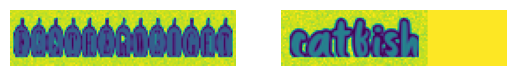

In [11]:
import matplotlib.pyplot as plt

num_images_to_display = 2 

for i in range(num_images_to_display):
    plt.subplot(1, num_images_to_display, i+1)
    plt.imshow(training_img[i])  
    plt.axis('off') 
plt.show()


In [13]:
print(orig_txt[:2])

['featherweight', 'catfish']


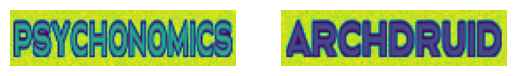

In [14]:
import matplotlib.pyplot as plt

num_images_to_display = 2 

for i in range(num_images_to_display):
    plt.subplot(1, num_images_to_display, i+1)  
    plt.imshow(valid_img[i])  
    plt.axis('off')  
plt.show()


In [16]:
print(valid_orig_txt[:2])

['psychonomics', 'archdruid']


In [15]:
train_padded_txt = pad_sequences(training_txt, maxlen=max_label_len, padding='post', value = len(char_list))
valid_padded_txt = pad_sequences(valid_txt, maxlen=max_label_len, padding='post', value = len(char_list))

In [30]:
inputs = Input(shape=(32,128,1))

conv_1 = Conv2D(64, (3,3), activation = 'relu', padding='same')(inputs)

pool_1 = MaxPool2D(pool_size=(2, 2), strides=2)(conv_1)
 
conv_2 = Conv2D(128, (3,3), activation = 'relu', padding='same')(pool_1)
pool_2 = MaxPool2D(pool_size=(2, 2), strides=2)(conv_2)
 
conv_3 = Conv2D(256, (3,3), activation = 'relu', padding='same')(pool_2)
 
conv_4 = Conv2D(256, (3,3), activation = 'relu', padding='same')(conv_3)

pool_4 = MaxPool2D(pool_size=(2, 1))(conv_4)
 
conv_5 = Conv2D(512, (3,3), activation = 'relu', padding='same')(pool_4)

batch_norm_5 = BatchNormalization()(conv_5)
 
conv_6 = Conv2D(512, (3,3), activation = 'relu', padding='same')(batch_norm_5)
batch_norm_6 = BatchNormalization()(conv_6)
pool_6 = MaxPool2D(pool_size=(2, 1))(batch_norm_6)
 
conv_7 = Conv2D(512, (2,2), activation = 'relu')(pool_6)
 
squeezed = Lambda(lambda x: K.squeeze(x, 1))(conv_7)
 
blstm_1 = Bidirectional(LSTM(128, return_sequences=True, dropout = 0.2))(squeezed)
blstm_2 = Bidirectional(LSTM(128, return_sequences=True, dropout = 0.2))(blstm_1)
 
outputs = Dense(len(char_list)+1, activation = 'softmax')(blstm_2)

act_model = Model(inputs, outputs)

In [23]:
act_model.summary()

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_4 (InputLayer)        [(None, 32, 128, 1)]      0         
                                                                 
 conv2d_21 (Conv2D)          (None, 32, 128, 64)       640       
                                                                 
 max_pooling2d_12 (MaxPoolin  (None, 16, 64, 64)       0         
 g2D)                                                            
                                                                 
 conv2d_22 (Conv2D)          (None, 16, 64, 128)       73856     
                                                                 
 max_pooling2d_13 (MaxPoolin  (None, 8, 32, 128)       0         
 g2D)                                                            
                                                                 
 conv2d_23 (Conv2D)          (None, 8, 32, 256)        2951

In [129]:
labels = Input(name='the_labels', shape=[max_label_len], dtype='float32')
input_length = Input(name='input_length', shape=[1], dtype='int64')
label_length = Input(name='label_length', shape=[1], dtype='int64')
 
 
def ctc_lambda_func(args):
    y_pred, labels, input_length, label_length = args
 
    return K.ctc_batch_cost(labels, y_pred, input_length, label_length)
 
 
loss_out = Lambda(ctc_lambda_func, output_shape=(1,), name='ctc')([outputs, labels, input_length, label_length])

model = Model(inputs=[inputs, labels, input_length, label_length], outputs=loss_out)

In [20]:
model.compile(loss={'ctc': lambda y_true, y_pred: y_pred}, optimizer = 'adam')
 
filepath="ctc_model.hdf5"
checkpoint = ModelCheckpoint(filepath=filepath, monitor='val_loss', verbose=1, save_best_only=True, mode='auto')
callbacks_list = [checkpoint]

In [21]:
training_img = np.array(training_img)
train_input_length = np.array(train_input_length)
train_label_length = np.array(train_label_length)

valid_img = np.array(valid_img)
valid_input_length = np.array(valid_input_length)
valid_label_length = np.array(valid_label_length)

In [22]:
training_img.shape

(81028, 32, 128, 1)

In [23]:
valid_img.shape

(9003, 32, 128, 1)

In [24]:
batch_size = 32
epochs = 20
history=model.fit(x=[training_img, train_padded_txt, train_input_length, train_label_length], y=np.zeros(len(training_img)), batch_size=batch_size, epochs = epochs, validation_data = ([valid_img, valid_padded_txt, valid_input_length, valid_label_length], [np.zeros(len(valid_img))]), verbose = 1, callbacks = callbacks_list)

2024-12-20 21:46:32.246826: W tensorflow/core/framework/cpu_allocator_impl.cc:82] Allocation of 1327562752 exceeds 10% of free system memory.
2024-12-20 21:46:33.987365: W tensorflow/core/framework/cpu_allocator_impl.cc:82] Allocation of 1327562752 exceeds 10% of free system memory.


Epoch 1/20


2024-12-20 21:46:54.671672: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8201


2533/2533 [==============================] - ETA: 0s - loss: 8.6179
Epoch 1: val_loss improved from inf to 0.87589, saving model to ctc_model.hdf5
2533/2533 [==============================] - 203s 55ms/step - loss: 8.6179 - val_loss: 0.8759
Epoch 2/20
2532/2533 [============================>.] - ETA: 0s - loss: 0.7179
Epoch 2: val_loss did not improve from 0.87589
2533/2533 [==============================] - 127s 50ms/step - loss: 0.7180 - val_loss: 1.0648
Epoch 3/20
2532/2533 [============================>.] - ETA: 0s - loss: 0.5630
Epoch 3: val_loss did not improve from 0.87589
2533/2533 [==============================] - 126s 50ms/step - loss: 0.5630 - val_loss: 0.8938
Epoch 4/20
2532/2533 [============================>.] - ETA: 0s - loss: 0.4740
Epoch 4: val_loss improved from 0.87589 to 0.54955, saving model to ctc_model.hdf5
2533/2533 [==============================] - 128s 50ms/step - loss: 0.4740 - val_loss: 0.5495
Epoch 5/20
2532/2533 [============================>.] - ETA: 0s

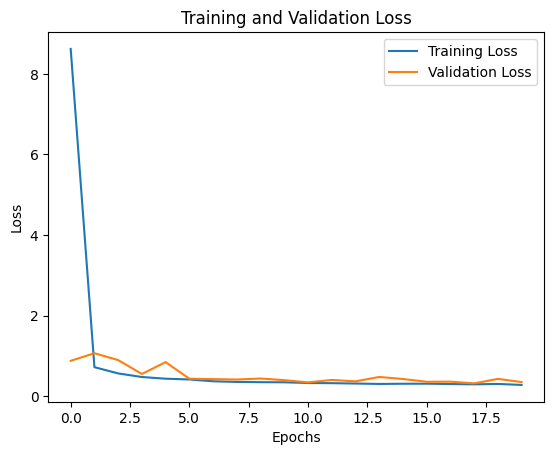

In [31]:
history_dict = history.history

plt.plot(history_dict['loss'], label='Training Loss')
plt.plot(history_dict['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')
plt.show()


In [26]:
act_model.load_weights('ctc_model.hdf5')
 
prediction = act_model.predict(valid_img[:10])
 
out = K.get_value(K.ctc_decode(prediction, input_length=np.ones(prediction.shape[0])*prediction.shape[1],
                         greedy=True)[0][0])
 
i = 0
for x in out:
    print("original_text =  ", valid_orig_txt[i])
    print("predicted text = ", end = '')
    for p in x:  
        if int(p) != -1:
            print(char_list[int(p)], end = '')       
    print('\n')
    i+=1

1/1 [==============================] - 1s 748ms/step
original_text =   psychonomics
predicted text = psychonomics

original_text =   archdruid
predicted text = archdruid

original_text =   preparing
predicted text = preparing

original_text =   spunk
predicted text = spunk

original_text =   insincerely
predicted text = insincerely

original_text =   atmidalbumin
predicted text = atmidalbumin

original_text =   repayed
predicted text = repayed

original_text =   gramophonist
predicted text = gramophonist

original_text =   Layland
predicted text = Layland

original_text =   AJC
predicted text = AC



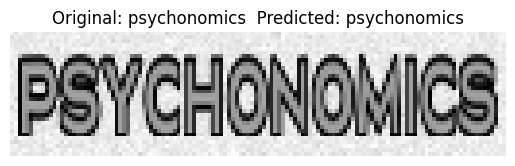

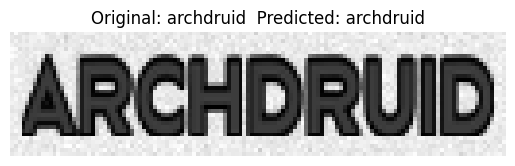

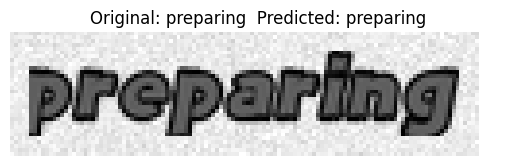

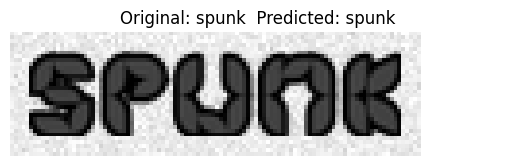

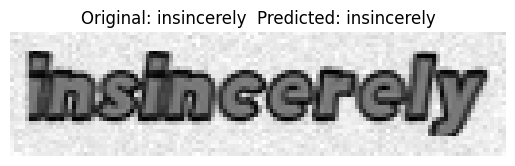

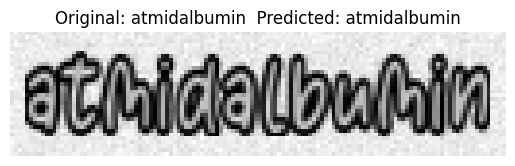

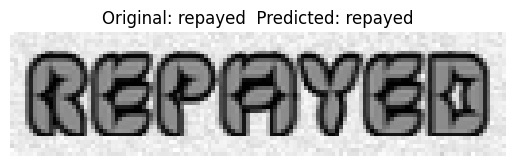

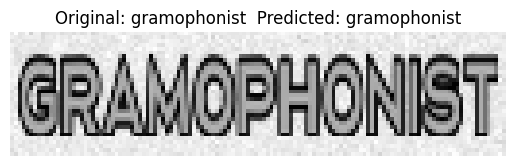

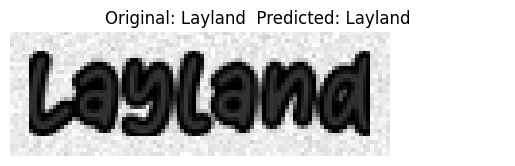

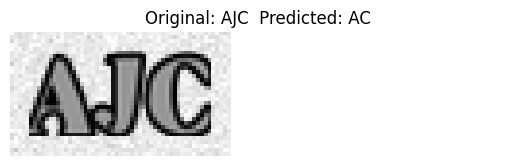

In [33]:
num_samples=10
for i in range(num_samples):
    img = valid_img[i].reshape(32, 128)
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.title(f"Original: {valid_orig_txt[i]}  Predicted: {out[i]}")
    plt.show()

In [4]:
!pip install editdistance

  Using cached editdistance-0.8.1-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (3.9 kB)
Using cached editdistance-0.8.1-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (401 kB)


In [29]:
predictions = act_model.predict(valid_img[::]) 

decoded_output = K.get_value(K.ctc_decode(predictions, input_length=np.ones(predictions.shape[0]) * predictions.shape[1], greedy=True)[0][0])

out = []
for x in decoded_output:
    pred_text = ''.join([char_list[int(p)] for p in x if int(p) != -1])  
    out.append(pred_text)


import editdistance

def calculate_cer(predictions, ground_truths):
    cer_total = 0
    for i, pred in enumerate(predictions):
        gt_text = ground_truths[i]  
        cer_total += editdistance.eval(pred, gt_text)  
    cer = cer_total / sum(len(gt) for gt in ground_truths)  
    return cer


cer = calculate_cer(out, valid_orig_txt)
print(f"CER: {cer * 100:.2f}%")


282/282 [==============================] - 3s 11ms/step
CER: 1.15%


In [30]:
def calculate_wer(predictions, ground_truths):
    wer_total = 0
    for i, pred in enumerate(predictions):
        gt_text = ground_truths[i]
        pred_words = pred.split() 
        gt_words = gt_text.split()  
        wer_total += editdistance.eval(pred_words, gt_words)  
    wer = wer_total / sum(len(gt.split()) for gt in ground_truths)  
    return wer

wer = calculate_wer(out, valid_orig_txt)
print(f"WER: {wer * 100:.2f}%")

WER: 9.32%


In [ ]:
model.save('ctc_crnn_model.h5')

In [51]:
import pandas as pd
datatrain =pd.read_csv("testdata.csv")
datatrain    

,ImgName,GroundTruth,smallLexi,mediumLexi
0,test/1002_1.png,PRIVATE,"['PRIVATE', '136', '17', '3SIDED', '55496002',...","['PRIVATE', '008', '02', '020', '05', '0726813..."
1,test/1002_2.png,PARKING,"['PARKING', '112009', '220', '227', '22A', '24...","['PARKING', '005216', '008', '02', '020', '072..."
2,test/1009_1.png,SALUTES,"['SALUTES', '167', 'AFFECTS', 'ANGELINA', 'BE'...","['SALUTES', '005216', '008', '01922', '02', '0..."
3,test/100_1.png,DOLCE,"['DOLCE', '1200PM', '2003', '40', '604', '6279...","['DOLCE', '005216', '01922', '02', '05', '0726..."
4,test/100_2.png,GABBANA,"['GABBANA', '08', '10DIGIT', '12', '19', '2010...","['GABBANA', '005216', '01922', '02', '05', '07..."
...,...,...,...,...
2995,test/997_9.png,DAY,"['DAY', '11', '31', '4567', 'AFFECTS', 'AFTER'...","['DAY', '005216', '008', '01922', '02', '05', ..."
2996,test/999_1.png,HOW,"['HOW', '1212', '26', '3602', '50TH', '53327',...","['HOW', '008', '01922', '02', '020', '05', '08..."
2997,test/999_6.png,AT,"['AT', '05', '100', '215', '222', '43', '604',...","['AT', '005216', '008', '01922', '02', '072681..."
2998,test/999_7.png,70,"['70', '123456', '2', '2419', '25', '46143994'...","['70', '005216', '01922', '02', '05', '08', '0..."


In [52]:
datatest=pd.read_csv("traindata.csv")
datatest 

,ImgName,GroundTruth,smallLexi,mediumLexi
0,train/1009_2.png,YOU,"['YOU', '1200', '1300', '135', '149', '324', '...","['YOU', '0', '000', '010050', '0123', '019901'..."
1,train/1017_1.png,RESCUE,"['RESCUE', '16', '208', '226', '300', '629', '...","['RESCUE', '0', '0123', '01234', '01922', '06'..."
2,train/1017_2.png,MISSION,"['MISSION', '0', '10234', '123', '1380', '2008...","['MISSION', '0', '000', '01234', '01922', '019..."
3,train/1021_1.png,HOME,"['HOME', '010050', '143KM', '2008', '208', '25...","['HOME', '0', '000', '010050', '01234', '01990..."
4,train/1023_1.png,BORDER,"['BORDER', '12', '143KM', '17', '2003', '2009'...","['BORDER', '0', '000', '010050', '0123', '0123..."
...,...,...,...,...
1995,train/997_7.png,FOR,"['FOR', '12345', '1300', '162', '165', '183', ...","['FOR', '0', '000', '0123', '01234', '01922', ..."
1996,train/999_2.png,TO,"['TO', '1', '12345', '124', '183', '22', '26',...","['TO', '0', '000', '010050', '0123', '01922', ..."
1997,train/999_3.png,WRITE,"['WRITE', '1200', '12TH', '212', '324', '4377'...","['WRITE', '0', '010050', '0123', '01234', '019..."
1998,train/999_4.png,GREAT,"['GREAT', '019901', '112009', '1472', '16', '2...","['GREAT', '000', '010050', '0123', '01234', '0..."


In [53]:
datatrain['images']="IIIT5K-Word_V3.0/IIIT5K/"+datatrain['ImgName']
datatrain['label']=datatrain['GroundTruth'].str.lower()
train_labels=datatrain['label'].tolist()
train_images=datatrain['images'].tolist()

In [54]:
datatest['images']="IIIT5K-Word_V3.0/IIIT5K/"+datatest['ImgName']
datatest['label']=datatest['GroundTruth'].str.lower()
valid_labels=datatest['label'].tolist()
valid_images=datatest['images'].tolist()

In [55]:
train_images[:2]

['IIIT5K-Word_V3.0/IIIT5K/test/1002_1.png',
 'IIIT5K-Word_V3.0/IIIT5K/test/1002_2.png']

In [81]:
paths=train_images+valid_images
labels=train_labels+valid_labels

In [82]:
char_list = list(set(char for label in train_labels for char in label))


char_to_index = {char: idx for idx, char in enumerate(char_list)}


In [83]:
inputs = Input(shape=(32,128,1))

conv_1 = Conv2D(64, (3,3), activation = 'relu', padding='same')(inputs)

pool_1 = MaxPool2D(pool_size=(2, 2), strides=2)(conv_1)
 
conv_2 = Conv2D(128, (3,3), activation = 'relu', padding='same')(pool_1)
pool_2 = MaxPool2D(pool_size=(2, 2), strides=2)(conv_2)
 
conv_3 = Conv2D(256, (3,3), activation = 'relu', padding='same')(pool_2)
 
conv_4 = Conv2D(256, (3,3), activation = 'relu', padding='same')(conv_3)

pool_4 = MaxPool2D(pool_size=(2, 1))(conv_4)
 
conv_5 = Conv2D(512, (3,3), activation = 'relu', padding='same')(pool_4)

batch_norm_5 = BatchNormalization()(conv_5)
 
conv_6 = Conv2D(512, (3,3), activation = 'relu', padding='same')(batch_norm_5)
batch_norm_6 = BatchNormalization()(conv_6)
pool_6 = MaxPool2D(pool_size=(2, 1))(batch_norm_6)
 
conv_7 = Conv2D(512, (2,2), activation = 'relu')(pool_6)
 
squeezed = Lambda(lambda x: K.squeeze(x, 1))(conv_7)
 
blstm_1 = Bidirectional(LSTM(128, return_sequences=True, dropout = 0.2))(squeezed)
blstm_2 = Bidirectional(LSTM(128, return_sequences=True, dropout = 0.2))(blstm_1)
 
outputs = Dense(len(char_list)+1, activation = 'softmax')(blstm_2)

act_model = Model(inputs, outputs)

In [66]:
act_model.load_weights("ctc_model.hdf5", by_name=True, skip_mismatch=True)

In [14]:
!pip install albumentations

  Using cached albumentations-1.4.23-py3-none-any.whl.metadata (36 kB)
  Using cached pydantic-2.10.4-py3-none-any.whl.metadata (29 kB)
  Using cached albucore-0.0.21-py3-none-any.whl.metadata (5.3 kB)
  Using cached stringzilla-3.11.2-cp310-cp310-manylinux_2_5_x86_64.manylinux1_x86_64.manylinux_2_28_x86_64.whl.metadata (80 kB)
  Using cached simsimd-6.2.1-cp310-cp310-manylinux_2_28_x86_64.whl.metadata (66 kB)
  Using cached annotated_types-0.7.0-py3-none-any.whl.metadata (15 kB)
  Using cached pydantic_core-2.27.2-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (6.6 kB)
Using cached albumentations-1.4.23-py3-none-any.whl (269 kB)
Using cached albucore-0.0.21-py3-none-any.whl (12 kB)
Using cached pydantic-2.10.4-py3-none-any.whl (431 kB)
Using cached pydantic_core-2.27.2-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (2.0 MB)
Using cached annotated_types-0.7.0-py3-none-any.whl (13 kB)
Using cached simsimd-6.2.1-cp310-cp310-manylinux_2_28_x86_64.whl (632 

In [69]:
import albumentations as A


In [91]:
import cv2
import numpy as np

def preprocess_images(paths, labels):
    training_img = []
    training_txt = []
    train_input_length = []
    train_label_length = []
    valid_img = []
    valid_txt = []
    valid_input_length = []
    valid_label_length = []

    max_label_len = 0

    for i, (path, label) in enumerate(zip(paths, labels)):
       
        img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2GRAY)
        h, w = img.shape
        
        

        if h > 32 or w > 128:
            img = cv2.resize(img, (128, 32))
            h, w = img.shape 

        
        if h < 32:
            add_zeros = np.ones((32 - h, w)) * 255
            img = np.concatenate((img, add_zeros), axis=0)
            h, w = img.shape  
            

        
        if w < 128:
            add_zeros = np.ones((h, 128 - w)) * 255
            img = np.concatenate((img, add_zeros), axis=1)
            h, w = img.shape  
            

        img = np.expand_dims(img, axis=2) / 255.0

        
        if len(label) > max_label_len:
            max_label_len = len(label)

       
        if i % 10 == 0:
            valid_img.append(img)
            valid_txt.append(label)
            valid_input_length.append(31)  
            valid_label_length.append(len(label))
        else:
            
            transform = A.Compose([
                        A.Rotate(limit=5, p=1.0),  # Random rotation
                        A.RandomCrop(height=32, width=128, p=1.0),  # Random cropping
                        A.ColorJitter(p=0.5),  # Random color jitter
                        A.GaussianBlur(p=0.2),
                        A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),  # Adjusting brightness and contrast
                        A.ElasticTransform(alpha=1.0, sigma=10, p=0.5)
                                      ])

            augmented_image = transform(image=img)['image']
            training_img.append(augmented_image)
            training_txt.append(label)
            train_input_length.append(31) 
            train_label_length.append(len(label))

 
    return {
        'training_img': training_img,
        'training_txt': training_txt,
        'train_input_length': train_input_length,
        'train_label_length': train_label_length,
        'valid_img': valid_img,
        'valid_txt': valid_txt,
        'valid_input_length': valid_input_length,
        'valid_label_length': valid_label_length,
        'max_label_len': max_label_len
    }



In [ ]:
result = preprocess_images(paths, labels)

training_img = result['training_img']
training_txt = result['training_txt']
train_input_length = result['train_input_length']
train_label_length = result['train_label_length']
valid_img = result['valid_img']
valid_txt = result['valid_txt']
valid_input_length = result['valid_input_length']
valid_label_length = result['valid_label_length']


In [204]:
for layer in act_model.layers: 
    layer.trainable = False


In [93]:
max_label_len=result['max_label_len']

In [94]:
def text_to_sequence(text, char_to_index):
    return [char_to_index[char] for char in text if char in char_to_index]


In [95]:

training_seq = [text_to_sequence(label, char_to_index) for label in training_txt]
train_padded_txt = pad_sequences(training_seq, maxlen=max_label_len, padding='post', value=len(char_list))

valid_seq = [text_to_sequence(label, char_to_index) for label in valid_txt]
valid_padded_txt = pad_sequences(valid_seq, maxlen=max_label_len, padding='post', value=len(char_list))

train_img = np.array(training_img)
train_input_length = np.array(train_input_length)
train_label_length = np.array(train_label_length)
valid_img = np.array(valid_img)
valid_input_length = np.array(valid_input_length)
valid_label_length = np.array(valid_label_length)


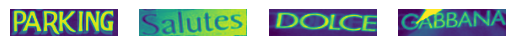

In [96]:
import matplotlib.pyplot as plt

num_images_to_display = 4

for i in range(num_images_to_display):
    plt.subplot(1, num_images_to_display, i+1)
    plt.imshow(train_img[i])  
    plt.axis('off') 
plt.show()

In [282]:
training_txt[:4]

['parking', 'salutes', 'dolce', 'gabbana']

In [97]:
from keras.optimizers import Adam
labels = Input(name='the_labels', shape=[max_label_len], dtype='float32')
input_length = Input(name='input_length', shape=[1], dtype='int64')
label_length = Input(name='label_length', shape=[1], dtype='int64')
 
 
def ctc_lambda_func(args):
    y_pred, labels, input_length, label_length = args
 
    return K.ctc_batch_cost(labels, y_pred, input_length, label_length)
 
 
loss_out = Lambda(ctc_lambda_func, output_shape=(1,), name='ctc')([outputs, labels, input_length, label_length])
low_lr = 1e-3
optimizer = Adam(learning_rate=low_lr)
model = Model(inputs=[inputs, labels, input_length, label_length], outputs=loss_out)
model.compile(loss={'ctc': lambda y_true, y_pred: y_pred}, optimizer = 'adam')
 
filepath="new_model.hdf5"
checkpoint = ModelCheckpoint(filepath=filepath, monitor='val_loss', verbose=1, save_best_only=True, mode='auto')
callbacks_list = [checkpoint]

In [98]:
batch_size = 32
epochs = 60

history=model.fit(x=[train_img, train_padded_txt, train_input_length, train_label_length], y=np.zeros(len(train_img)), batch_size=batch_size, epochs = epochs, validation_data = ([valid_img, valid_padded_txt, valid_input_length, valid_label_length], [np.zeros(len(valid_img))]), verbose = 1, callbacks = callbacks_list)

Epoch 1/60
140/141 [============================>.] - ETA: 0s - loss: 18.7212
Epoch 1: val_loss improved from inf to 17.70012, saving model to new_model.hdf5
141/141 [==============================] - 17s 70ms/step - loss: 18.6982 - val_loss: 17.7001
Epoch 2/60
141/141 [==============================] - ETA: 0s - loss: 17.3800
Epoch 2: val_loss improved from 17.70012 to 17.05159, saving model to new_model.hdf5
141/141 [==============================] - 8s 55ms/step - loss: 17.3800 - val_loss: 17.0516
Epoch 3/60
141/141 [==============================] - ETA: 0s - loss: 17.0979
Epoch 3: val_loss improved from 17.05159 to 16.70384, saving model to new_model.hdf5
141/141 [==============================] - 8s 55ms/step - loss: 17.0979 - val_loss: 16.7038
Epoch 4/60
141/141 [==============================] - ETA: 0s - loss: 16.8009
Epoch 4: val_loss did not improve from 16.70384
141/141 [==============================] - 7s 51ms/step - loss: 16.8009 - val_loss: 17.4435
Epoch 5/60
140/141 [=

In [99]:
act_model.load_weights('new_model.hdf5')

prediction = act_model.predict(valid_img[:10])
out = K.get_value(K.ctc_decode(prediction, input_length=np.ones(prediction.shape[0]) * prediction.shape[1], greedy=True)[0][0])

for i, x in enumerate(out):
    print("Original text = ", valid_txt[i])
    print("Predicted text = ", ''.join([char_list[int(p)] for p in x if int(p) != -1]))
    print('\n')


1/1 [==============================] - 2s 2s/step
Original text =  private
Predicted text =  prwate


Original text =  kingfisher
Predicted text =  pogesser


Original text =  loans
Predicted text =  loans


Original text =  bank
Predicted text =  behk


Original text =  gypsy
Predicted text =  chpsy


Original text =  regency
Predicted text =  regency


Original text =  state
Predicted text =  stnte


Original text =  bank
Predicted text =  bank


Original text =  by
Predicted text =  by


Original text =  550
Predicted text =  50




In [100]:
import editdistance

def calculate_cer(predictions, ground_truths):
    cer_total = 0
    for i, pred in enumerate(predictions):
        gt_text = ground_truths[i]  
        cer_total += editdistance.eval(pred, gt_text)  
    cer = cer_total / sum(len(gt) for gt in ground_truths)  
    return cer

def calculate_wer(predictions, ground_truths):
    wer_total = 0
    for i, pred in enumerate(predictions):
        gt_text = ground_truths[i]
        pred_words = pred.split() 
        gt_words = gt_text.split()  
        wer_total += editdistance.eval(pred_words, gt_words)  
    wer = wer_total / sum(len(gt.split()) for gt in ground_truths)  
    return wer

predictions = act_model.predict(valid_img)
decoded_output = K.get_value(K.ctc_decode(predictions, input_length=np.ones(predictions.shape[0]) * predictions.shape[1], greedy=True)[0][0])


decoded_predictions = [''.join([char_list[int(p)] for p in x if int(p) != -1]) for x in decoded_output]


cer = calculate_cer(decoded_predictions, valid_txt)
print(f"CER: {cer * 100:.2f}%")

wer = calculate_wer(decoded_predictions, valid_txt)
print(f"WER: {wer * 100:.2f}%")


16/16 [==============================] - 0s 17ms/step
CER: 36.09%
WER: 72.00%


In [244]:
act_model.load_weights('finetuned_model.hdf5')

prediction = act_model.predict(valid_img[:10])
out = K.get_value(K.ctc_decode(prediction, input_length=np.ones(prediction.shape[0]) * prediction.shape[1], greedy=True)[0][0])

for i, x in enumerate(out):
    print("Original text = ", valid_txt[i])
    print("Predicted text = ", ''.join([char_list[int(p)] for p in x if int(p) != -1]))
    print('\n')


1/1 [==============================] - 0s 38ms/step
Original text =  private
Predicted text =  private


Original text =  kingfisher
Predicted text =  togester


Original text =  loans
Predicted text =  loans


Original text =  bank
Predicted text =  bark


Original text =  gypsy
Predicted text =  gypsy


Original text =  regency
Predicted text =  regency


Original text =  state
Predicted text =  state


Original text =  bank
Predicted text =  bank


Original text =  by
Predicted text =  by


Original text =  550
Predicted text =  360




In [245]:
import editdistance

def calculate_cer(predictions, ground_truths):
    cer_total = 0
    for i, pred in enumerate(predictions):
        gt_text = ground_truths[i]  
        cer_total += editdistance.eval(pred, gt_text)  
    cer = cer_total / sum(len(gt) for gt in ground_truths)  
    return cer

def calculate_wer(predictions, ground_truths):
    wer_total = 0
    for i, pred in enumerate(predictions):
        gt_text = ground_truths[i]
        pred_words = pred.split() 
        gt_words = gt_text.split()  
        wer_total += editdistance.eval(pred_words, gt_words)  
    wer = wer_total / sum(len(gt.split()) for gt in ground_truths)  
    return wer

predictions = act_model.predict(valid_img)
decoded_output = K.get_value(K.ctc_decode(predictions, input_length=np.ones(predictions.shape[0]) * predictions.shape[1], greedy=True)[0][0])

decoded_predictions = [''.join([char_list[int(p)] for p in x if int(p) != -1]) for x in decoded_output]


cer = calculate_cer(decoded_predictions, valid_txt)
print(f"CER: {cer * 100:.2f}%")

wer = calculate_wer(decoded_predictions, valid_txt)
print(f"WER: {wer * 100:.2f}%")


16/16 [==============================] - 0s 16ms/step
CER: 29.30%
WER: 62.80%
